# Second-harmonic generation
Let us see how a crystal without inversion symmetry emits light at twice the frequency of the
light that drives it, with `h.get_shg_susceptibility()`. A field at frequency $\omega$ gives a
current at $2\omega$, $J_a(2\omega)=\sigma_{abc}E_b(\omega)E_c(\omega)$, and the susceptibility
$\chi_{abc}=i\sigma_{abc}/(2\omega\epsilon_0)$ is what an SHG experiment measures. It is computed
for the tight-binding model with its velocity and its second and third k-derivatives, which
makes it exact for any number of bands. For a two-dimensional system it is returned as a sheet
susceptibility in nm$^2$/V, given the length unit of the geometry in Å and the energy unit of
the Hamiltonian in eV.
### Import the necessary libraries

In [1]:
# Add the root path of the pyqula library
import os ; import sys
sys.path.append(os.getcwd()+"/../../../src")

import numpy as np
import matplotlib.pyplot as plt
from pyqula import geometry

### Resonances of a gapped honeycomb lattice
We take the honeycomb lattice with a staggered onsite energy $\pm m$, the two-band model of
hexagonal boron nitride, with $t=2.33$ eV and bond length 1.45 Å. The map shows
$\mathrm{Im}\,\chi_{xxx}$ as a function of the frequency and of $m$, with $x$ along the armchair
direction. The dashed lines are half the gap and the gap, $2m$ at the K point, and the dotted
line is half the transition energy at the M point, $2\sqrt{m^2+t^2}$.

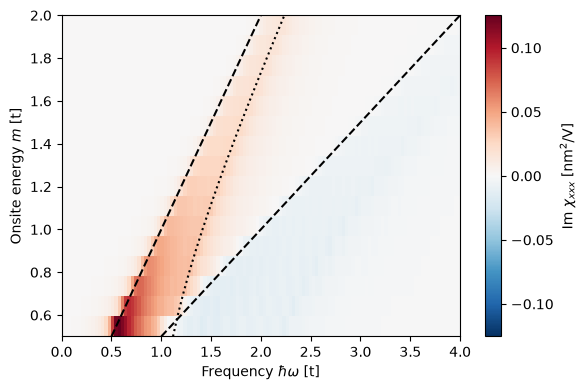

In [2]:
g = geometry.honeycomb_lattice() # x is the armchair direction
ms = np.linspace(0.5,2.0,16) # staggered onsite energies, in units of t
ws = np.linspace(0.,4.,121) # frequencies, in units of t
chis = [] # storage
for m in ms:
    h = g.get_hamiltonian(has_spin=True) # spinful, both spins are counted
    h.add_sublattice_imbalance(m) # onsite +-m
    (w,chi) = h.get_shg_susceptibility(energies=ws,nk=60,T=0.,delta=0.04,
                                       components="xxx",length_unit=1.45,
                                       energy_unit=2.33)
    chis.append(chi)
chis = np.array(chis)

plt.figure(figsize=(6,4))
plt.imshow(chis.imag,origin="lower",aspect="auto",cmap="RdBu_r",
           extent=[ws[0],ws[-1],ms[0],ms[-1]],
           vmin=-np.max(np.abs(chis.imag)),vmax=np.max(np.abs(chis.imag)))
plt.colorbar(label=r"Im $\chi_{xxx}$ [nm$^2$/V]")
plt.plot(ms,ms,c="black",ls="--") # half the gap, 2w = 2m
plt.plot(2*ms,ms,c="black",ls="--") # the gap, w = 2m
plt.plot(np.sqrt(ms**2+1.),ms,c="black",ls=":") # half the M transition
plt.xlim(ws[0],ws[-1])
plt.xlabel(r"Frequency $\hbar\omega$ [t]") ; plt.ylabel("Onsite energy $m$ [t]")
plt.tight_layout()
plt.show()

The response is absorptive only above half the gap, the left dashed line, where $2\hbar\omega$
can create an electron-hole pair at K. Between half the gap and half the M transition, the
dotted line, $\mathrm{Im}\,\chi_{xxx}$ is large and positive, and it is largest just above half
the gap for small $m$. Above the gap, the right dashed line, $\hbar\omega$ alone is resonant and
gives a weaker, negative contribution. As $m$ grows the whole spectrum moves up and becomes
weaker. For $m=0$ the lattice is graphene, which has inversion
symmetry, and $\chi_{xxx}$ is zero at every frequency.

### Symmetry: the $D_{3h}$ pattern and inversion
For a single layer the point group is $D_{3h}$, and the only nonzero components are
$\chi_{xxx}=-\chi_{xyy}=-\chi_{yxy}=-\chi_{yyx}$. We check this, and then stack two layers, the
second one the inversion image of the first, coupled by a vertical hopping 0.3. The
centrosymmetric bilayer gives zero. Making the two layers different, with a different onsite
energy, gives a signal again.

xxx [0.002578+0.j       0.003813+0.000141j]
xyy [-0.002578-0.j       -0.003813-0.000141j]
yxy [-0.002578+0.j       -0.003813-0.000141j]
yyx [-0.002578+0.j       -0.003813-0.000141j]
yyy [-0.-0.j -0.+0.j]


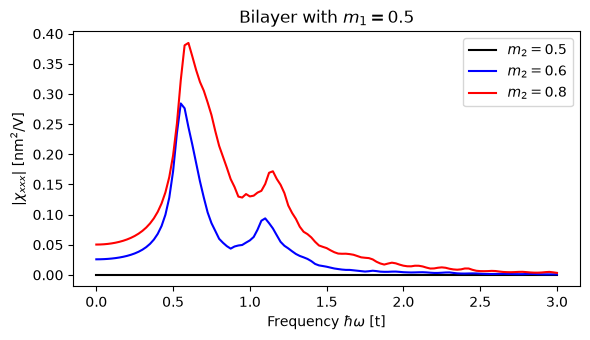

In [3]:
The single layer follows the $D_{3h}$ pattern, and $\chi_{yyy}$ is zero to machine
precision. The bilayer with two equal layers is centrosymmetric and its response is zero at
every frequency. With $m_2\neq m_1$ the two layers no longer cancel, and the signal grows with
the difference. The small wiggles above $\hbar\omega=1.5t$ are the discrete k-mesh, `nk=60`, at
this broadening. This is the mechanism behind the odd-even rule of 2H stacks of transition
metal dichalcogenides, where an even number of layers gives almost no SHG.

The single layer follows the $D_{3h}$ pattern, and $\chi_{yyy}$ is zero to machine
precision. The bilayer with two equal layers is centrosymmetric and its response is zero at
every frequency. With $m_2\neq m_1$ the two layers no longer cancel, and the signal grows with
the difference. This is the mechanism behind the odd-even rule of 2H stacks of transition
metal dichalcogenides, where an even number of layers gives almost no SHG.

### Comparison with the literature
The calculation uses the density-matrix recursion of Ref. [1] in the velocity gauge, with the
second- and third-derivative vertices of the tight-binding Hamiltonian, which is why the
two-band model gives a finite result: without these vertices a two-band model gives zero, the
failure of the truncated velocity gauge discussed in Ref. [2]. The resonance structure, with
features at half the transition energies and a strong peak at half the van Hove transition, is
the one found for hBN in Ref. [2] and for monolayer MoS$_2$ in Ref. [3], where the odd-even layer
rule is also discussed.

[1] D. J. Passos et al., *Nonlinear optical responses of crystalline systems: Results from a
velocity gauge analysis*, Phys. Rev. B **97**, 235446 (2018),
[arXiv:1712.04924](https://arxiv.org/abs/1712.04924)

[2] A. Taghizadeh, F. Hipolito, T. G. Pedersen, *Linear and nonlinear optical response of
crystals using length and velocity gauges: Effect of basis truncation*, Phys. Rev. B **96**,
195413 (2017), [arXiv:1710.01300](https://arxiv.org/abs/1710.01300)

[3] M. L. Trolle, G. Seifert, T. G. Pedersen, *Theory of second harmonic generation in
few-layered MoS$_2$*, Phys. Rev. B **89**, 235410 (2014),
[arXiv:1310.0674](https://arxiv.org/abs/1310.0674)